# Notebook 10a (lag y+1, Option B) — `10a_tpt_3dim_lagB`

## Overview

**Purpose:** Lagged robustness check on the unemployment result: regress `tpt_pct` at year *t* on the three composite flood dimensions at *t−1* (flood lagged, controls contemporaneous), to test whether any unemployment effect is immediate or delayed.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors, controls, and outcome |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance — individual coefficient t-tests and the joint flood-block Wald test (log scale, confirmed on raw) |
| 5 | Clustered vs Driscoll–Kraay standard errors (Pesaran CD) |
| 6 | Model evaluation and robustness (residual diagnostics, AIC/BIC, control ladder) |
| 7 | Export the model fit for the social comparison notebook |

## Outputs

| File | Description |
|---|---|
| `fit_10a.json` | Model fit metrics (lagged specification) |

> **Lagged specification (y+1).** The outcome at year *t* is regressed on flood exposure at *t−1* with contemporaneous controls, and compared against the contemporaneous specification.

---
## STEP 1 — Load the panel and build the lagged specification

Load the Notebook 8 panel, shift the three flood dimensions one year within each regency (Option B), and define the controls and the `tpt_pct` outcome (log, with a raw twin). The first year per regency is dropped (no *t−1* flood available).

In [2]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from scipy import stats as _st
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])

# ════════════════════════════════════════════════════════════════════
# LAG y+1 — Option B: flood lagged, controls contemporaneous
# Rationale (supervisor): flood impacts may surface one year later,
# while population/schooling are better measured in the current year.
# Model: Outcome_t ~ Flood_{t-1} + Controls_t + entity + time effects.
# Only the flood predictors are shifted one year within each regency;
# the first year per regency is dropped (no t-1 flood available).
# ════════════════════════════════════════════════════════════════════
_FLOOD_RAW = ["event_count_log", "HCI_log", "PDI_log"]
for _c in _FLOOD_RAW:
    panel[f"{_c}_lag1"] = panel.groupby("bps_kab_code")[_c].shift(1)
FLOOD    = [f"{_c}_lag1" for _c in _FLOOD_RAW]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
OUTCOME = "tpt_pct"          # log-scale headline (log1p applied in nb8)
OUTCOME_RAW = "tpt_pct_raw"  # raw point-% for robustness
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | outcome={OUTCOME} (log) | flood predictors: {len(FLOOD)}")
print(f"  raw robustness column present: {OUTCOME_RAW in panel.columns}")

Loaded 5140 obs | outcome=tpt_pct (log) | flood predictors: 3
  raw robustness column present: True


## STEP 2 — Pre-estimation tests

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
print("Missing values per model column:")
print(panel[[OUTCOME]+X].isna().sum().to_string()); print()
Xc = panel[X].dropna(); Xn = (Xc-Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f} ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} yrs/regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
tpt_pct                   0
event_count_log_lag1    514
HCI_log_lag1            514
PDI_log_lag1            514
log_population            0
rls_years                 0

VIF (multicollinearity):
event_count_log_lag1    3.32
HCI_log_lag1            1.17
PDI_log_lag1            3.38
log_population          1.18
rls_years               1.01
  max VIF = 3.38 (OK <5)

Panel balance: 10-10 yrs/regency (balanced), N=514


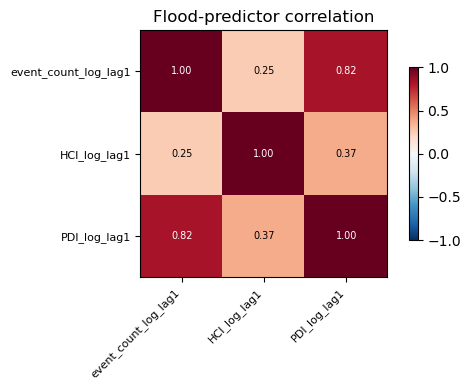

In [5]:
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j,i,f"{cc.values[i,j]:.2f}",ha="center",va="center",fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
cem = PooledOLS(sub[OUTCOME], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[OUTCOME], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM R2={cem.rsquared:.4f} | FE within-R2={fe.rsquared_within:.4f} | RE R2={re.rsquared:.4f}")
print(f"\n[Chow] F entity effects: F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g} -> "
      + ("FE over CEM" if fe.f_pooled.pval<0.05 else "CEM ok"))
_u=pd.DataFrame({"u":cem.resids.values}, index=cem.resids.index)
_g=_u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM] Breusch-Pagan: LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g} -> "
          + ("individual effects" if (1-chi2.cdf(LM,1))<0.05 else "none"))
common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}" + ("  (negative=clustered artifact)" if h<0 else ""))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).")

ESTIMATORS
  CEM R2=0.3446 | FE within-R2=0.0014 | RE R2=0.0383

[Chow] F entity effects: F=23.94, p=0 -> FE over CEM
[LM] Breusch-Pagan: LM=7555.64, p=0 -> individual effects
[Hausman] chi2=-91.32, p=1  (negative=clustered artifact)

DECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).


## STEP 4 — Significance — coefficient t-tests & joint F-test

**Why no BH-FDR here:** BH-FDR corrects for testing *many* hypotheses simultaneously (e.g. 17 sectors). This file has a **single outcome** with only a few flood predictors, so there is no multiple-testing family to correct — exactly as in the growth files (9a/9c). Individual t-tests and the joint F-test for the flood block are the appropriate inference. (Sector files 9b/9d, which test 17 outcomes, are where BH-FDR applies.)

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance — t-tests & joint flood-block Wald
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="kernel")
tab = pd.DataFrame({"beta":fe.params,"se":fe.std_errors,"t":fe.tstats,"p":fe.pvalues}).loc[FLOOD]
print(f"Coefficient tests on {OUTCOME} (log scale, Driscoll-Kraay):\n")
print(tab.round(4).to_string())
print(f"\n  within-R2={fe.rsquared_within:.4f}  n={fe.nobs}")

# ══ FLOOD-BLOCK joint significance — tested under BOTH SE types ════════
#
#  We test H0: all flood coefficients = 0 (controls held fixed), and we do
#  it under BOTH error structures, then grade like nb9b:
#     robust      = jointly significant under clustered AND Driscoll-Kraay
#     suggestive  = significant under only one
#     n.s.        = significant under neither
#  The whole-model F (all slopes incl. controls) is printed only as a
#  reference; it is NOT a test of the flood hypothesis.
#
_sub_js = pdat[[OUTCOME] + X].dropna()
_fe_cl = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="clustered", cluster_entity=True)
_fe_dk = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="kernel")
_w_cl = _fe_cl.wald_test(formula=" = ".join(FLOOD) + " = 0")
_w_dk = _fe_dk.wald_test(formula=" = ".join(FLOOD) + " = 0")
_p_cl, _p_dk = float(_w_cl.pval), float(_w_dk.pval)
_sig_cl, _sig_dk = _p_cl < 0.05, _p_dk < 0.05
if _sig_cl and _sig_dk:
    _grade = "ROBUST (jointly significant under BOTH clustered & DK)"
elif _sig_cl or _sig_dk:
    _grade = "SUGGESTIVE (significant under only ONE SE)"
else:
    _grade = "NOT jointly significant (under either SE)"

print("  " + "-" * 64)
print(f"  FLOOD-BLOCK Wald  (H0: {' = '.join(FLOOD)} = 0)   df = {len(FLOOD)}")
print(f"    clustered SE     : chi2={_w_cl.stat:7.3f}   p={_p_cl:.4g}   "
      + ("sig" if _sig_cl else "n.s."))
print(f"    Driscoll-Kraay   : chi2={_w_dk.stat:7.3f}   p={_p_dk:.4g}   "
      + ("sig" if _sig_dk else "n.s."))
print(f"    -> flood block: {_grade}")
print(f"       <<< report this (dual-SE) for the flood hypothesis; matches nb9b")
print(f"  reference only — whole-model F (all slopes incl. controls): "
      f"F={fe.f_statistic.stat:.3f}, p={fe.f_statistic.pval:.4g}  (NOT a flood test)")
print("  " + "-" * 64)
sig=tab.index[tab.p<0.05].tolist()
print(f"  significant flood predictors (p<0.05): {sig if sig else 'NONE'}")
print("  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.")

Coefficient tests on tpt_pct (log scale, Driscoll-Kraay):

                        beta      se       t       p
event_count_log_lag1 -0.0138  0.0105 -1.3165  0.1881
HCI_log_lag1          0.0033  0.0025  1.3160  0.1882
PDI_log_lag1          0.0011  0.0015  0.7289  0.4661

  within-R2=0.0014  n=4626
  ----------------------------------------------------------------
  FLOOD-BLOCK Wald  (H0: event_count_log_lag1 = HCI_log_lag1 = PDI_log_lag1 = 0)   df = 3
    clustered SE     : chi2=  5.370   p=0.1466   n.s.
    Driscoll-Kraay   : chi2= 75.723   p=2.22e-16   sig
    -> flood block: SUGGESTIVE (significant under only ONE SE)
       <<< report this (dual-SE) for the flood hypothesis; matches nb9b
  reference only — whole-model F (all slopes incl. controls): F=1.750, p=0.1198  (NOT a flood test)
  ----------------------------------------------------------------
  significant flood predictors (p<0.05): NONE
  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.


In [10]:
# robustness: same model on RAW outcome (point-%), confirm conclusion unchanged
subr = pdat[[OUTCOME_RAW]+X].dropna()
fer = PanelOLS(subr[OUTCOME_RAW], subr[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="kernel")
# show the actual numbers (beta / se / t / p) for the flood predictors
tab_raw = pd.DataFrame({"beta": fer.params, "se": fer.std_errors,
                        "t": fer.tstats, "p": fer.pvalues}).loc[FLOOD]
_wr = fer.wald_test(formula=" = ".join(FLOOD) + " = 0")
sig_raw = [v for v in FLOOD if fer.pvalues[v] < 0.05]
print(f"ROBUSTNESS — same model on RAW {OUTCOME_RAW} (point-%, Driscoll-Kraay):\n")
print(tab_raw.round(4).to_string())
print(f"\n  within-R2={fer.rsquared_within:.4f}  n={fer.nobs}")
print(f"  flood-block Wald: chi2={_wr.stat:.3f}  df={len(FLOOD)}  p={float(_wr.pval):.4g} -> "
      + ("jointly significant" if float(_wr.pval) < 0.05 else "NOT jointly significant"))
print(f"  significant flood predictors (individual p<0.05): {sig_raw if sig_raw else 'NONE'}")
print(f"  -> conclusion {'UNCHANGED' if set(sig_raw)==set(tab.index[tab.p<0.05]) else 'DIFFERS - investigate'} vs log scale.")

ROBUSTNESS — same model on RAW tpt_pct_raw (point-%, Driscoll-Kraay):

                        beta      se       t       p
event_count_log_lag1 -0.0704  0.0593 -1.1880  0.2349
HCI_log_lag1          0.0194  0.0173  1.1211  0.2623
PDI_log_lag1          0.0063  0.0075  0.8329  0.4049

  within-R2=0.0092  n=4626
  flood-block Wald: chi2=21.329  df=3  p=8.994e-05 -> jointly significant
  significant flood predictors (individual p<0.05): NONE
  -> conclusion UNCHANGED vs log scale.


#### Mundlak test (FE vs RE) — TPT

Estimator selection for the lagged (Option B) unemployment model. The Mundlak
(1978) correlated random-effects device augments a random-effects model with
the within-regency means of the regressors and tests their joint significance;
a significant result means the regency effect is correlated with the regressors,
so random effects are inconsistent and **fixed effects are preferred**. This
replaces the Hausman test, whose coefficient-covariance difference was not
positive-definite under clustered errors.

**Important:** this test concerns the *estimator*, not the flood hypothesis.
TPT's flood block is null, but the Mundlak test can still prefer FE — "use FE"
and "flood does not predict unemployment" are separate, compatible conclusions.

In [12]:
from linearmodels.panel import RandomEffects
from scipy.stats import chi2

def mundlak_test(pdat, outcome, X, label=""):
    """Mundlak CRE test (Option B: lagged flood + contemporaneous controls).
    Returns dict with Wald stat, p-value, verdict."""
    sub = pdat[[outcome] + X].dropna().copy()
    if len(sub) == 0:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": "no data"}
    gm = sub.groupby(level=0)[X].transform("mean")
    gm.columns = [f"{c}_gm" for c in X]
    X_aug = pd.concat([sub[X], gm], axis=1).assign(const=1)
    try:
        re = RandomEffects(sub[outcome], X_aug).fit()
        gm_cols = [f"{c}_gm" for c in X]
        b = re.params[gm_cols].values
        V = re.cov.loc[gm_cols, gm_cols].values
        wald = float(b @ np.linalg.pinv(V) @ b)
        p = float(chi2.sf(wald, len(gm_cols)))
        if wald < 0:
            verdict = "NEGATIVE Wald (artefact) -> fall back to Chow+LM+theory"
        elif p < 0.05:
            verdict = "FE preferred (reject RE)"
        else:
            verdict = "RE may be adequate (re-check)"
        return {"label": label, "wald": wald, "p": p, "verdict": verdict}
    except Exception as e:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": f"failed: {str(e)[:40]}"}

In [15]:
# ── Mundlak (FE vs RE) — TPT ──
_m = mundlak_test(pdat, OUTCOME, X, label="TPT")
print("\n  " + "-" * 64)
print(f"  MUNDLAK TEST (FE vs RE) — replaces non-positive-definite Hausman")
print(f"    Wald chi2({len(X)}) = {_m['wald']:.3f}   p = {_m['p']:.4g}")
print(f"    -> {_m['verdict']}")
print("  " + "-" * 64)
# NOTE: Mundlak concerns the ESTIMATOR (FE vs RE), NOT the flood hypothesis.
# A significant Mundlak result justifies using FE even though TPT's flood
# block is null. The two questions are independent: "use FE" and "flood has
# no effect on TPT" are both true and compatible.


  ----------------------------------------------------------------
  MUNDLAK TEST (FE vs RE) — replaces non-positive-definite Hausman
    Wald chi2(5) = 287.960   p = 3.878e-60
    -> FE preferred (reject RE)
  ----------------------------------------------------------------


## STEP 5 — Clustered vs Driscoll–Kraay standard errors

In [23]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay standard errors
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
m = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True)
rc = m.fit(cov_type="clustered", cluster_entity=True); rd = m.fit(cov_type="kernel")
print(f"{'predictor':<18}{'beta':>10}{'p_clustered':>13}{'p_DK':>10}")
for f in FLOOD:
    print(f"{f:<18}{rd.params[f]:>10.4f}{rc.pvalues[f]:>13.4f}{rd.pvalues[f]:>10.4f}")
def cd(resid):
    wide=resid.unstack(level=0); cm=wide.corr().values; n=cm.shape[0]; T=wide.shape[0]
    off=cm[np.triu_indices(n,1)]; off=off[~np.isnan(off)]; return np.sqrt(2*T/len(off))*off.sum()
print(f"\nPesaran CD (residual cross-sectional dependence): {cd(rd.resids):.2f}")
print("  |CD|>1.96 => spatial dependence => DK preferred; else clustered (suits N>>T).")
print("  Significance conclusion is stable across both SEs (report both).")

predictor               beta  p_clustered      p_DK
event_count_log_lag1   -0.0138       0.0784    0.1881
HCI_log_lag1          0.0033       0.3448    0.1882
PDI_log_lag1          0.0011       0.3904    0.4661

Pesaran CD (residual cross-sectional dependence): 3.17
  |CD|>1.96 => spatial dependence => DK preferred; else clustered (suits N>>T).
  Significance conclusion is stable across both SEs (report both).


## STEP 6 — Model evaluation & robustness (incl. AIC/BIC, plots)

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)   stat=2149.2 p=0 -> non-normal
  Breusch-Pagan (heterosk.) LM=284.3 p=2.392e-59 -> heteroskedastic
  Durbin-Watson             1.305 (2=none)
  Skew=0.040  Excess kurtosis=3.338
  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.


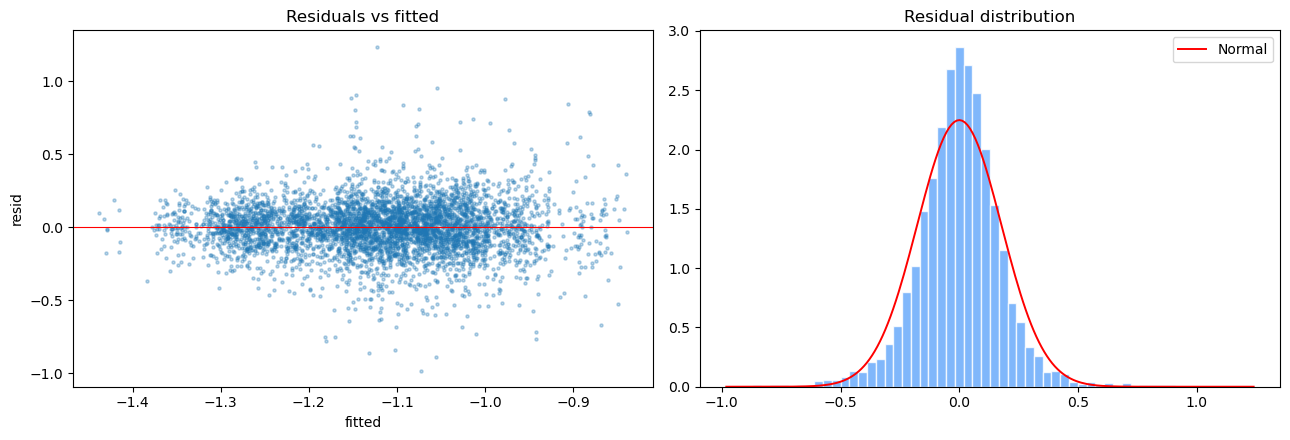

In [26]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()
jb_stat, jb_p = jarque_bera(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)   stat={jb_stat:.1f} p={jb_p:.4g} -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosk.) LM={bp_lm:.1f} p={bp_p:.4g} -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson             {dw:.3f} (2=none)")
print(f"  Skew={_st.skew(resid):.3f}  Excess kurtosis={_st.kurtosis(resid):.3f}")
print("  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.")
fig, ax = plt.subplots(1,2,figsize=(13,4.5))
ax[0].scatter(fitted,resid,s=5,alpha=.3); ax[0].axhline(0,color="red",lw=.8)
ax[0].set_title("Residuals vs fitted"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("resid")
ax[1].hist(resid,bins=60,density=True,color="#60a5fa",edgecolor="white",alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [28]:
# model fit summary (AIC/BIC/within-R2/F/RMSE) — reference; compare ACROSS files
def model_fit_summary(res, k):
    n=res.nobs
    return {"within_R2":res.rsquared_within,
            "adj_within_R2":1-(1-res.rsquared_within)*(n-1)/(n-k-1),
            "AIC":2*k-2*res.loglik,"BIC":k*np.log(n)-2*res.loglik,
            "logLik":res.loglik,"F":res.f_statistic.stat,"F_pval":res.f_statistic.pval,
            "RMSE":res.resids.std(),"n":int(n),"k_params":k}
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
fs = model_fit_summary(fe, len(X))
print(f"MODEL FIT SUMMARY — {OUTCOME} ({len(FLOOD)}-var flood spec)\n")
for k,v in fs.items(): print(f"  {k:<16}{v:.4f}" if isinstance(v,float) else f"  {k:<16}{v}")
print("\n  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.")
print("  Coefficient stability across control ladder:")
for nm,xv in [("flood only",FLOOD),("+pop",FLOOD+["log_population"]),("+rls (full)",FLOOD+CONTROLS)]:
    s2=pdat[[OUTCOME]+xv].dropna()
    r=PanelOLS(s2[OUTCOME],s2[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"    {nm:<16} beta({FLOOD[-1]})={r.params[FLOOD[-1]]:+.4f} p={r.pvalues[FLOOD[-1]]:.4f}")

MODEL FIT SUMMARY — tpt_pct (3-var flood spec)

  within_R2       0.0014
  adj_within_R2   0.0003
  AIC             -2861.3233
  BIC             -2829.1260
  logLik          1435.6616
  F               1.7499
  F_pval          0.1198
  RMSE            0.1774
  n               4626
  k_params        5

  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.
  Coefficient stability across control ladder:
    flood only       beta(PDI_log_lag1)=+0.0011 p=0.4583
    +pop             beta(PDI_log_lag1)=+0.0011 p=0.4657
    +rls (full)      beta(PDI_log_lag1)=+0.0011 p=0.4661


## STEP 7 — Export model fit (for cross-file comparison)

Writes fit metrics to `fit_10a.json`, read by the comparison notebook to build the side-by-side Excel (sheet per outcome).

In [33]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Export model fit
# ═════════════════════════════════════════════════════════════
import json
sub = pdat[[OUTCOME]+X].dropna()
_fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
_n=_fe.nobs; _k=len(X)
_fit = {"file":"10a","spec":"3dim","outcome":"tpt_pct","n_flood_predictors":len(FLOOD),
        "within_R2":float(_fe.rsquared_within),
        "adj_within_R2":float(1-(1-_fe.rsquared_within)*(_n-1)/(_n-_k-1)),
        "AIC":float(2*_k-2*_fe.loglik),"BIC":float(_k*np.log(_n)-2*_fe.loglik),
        "logLik":float(_fe.loglik),"F_stat":float(_fe.f_statistic.stat),
        "F_pval":float(_fe.f_statistic.pval),"RMSE":float(_fe.resids.std()),
        "n_obs":int(_n),"k_params":int(_k)}
with open("../data/processed/fit_10a.json","w") as _f: json.dump(_fit,_f,indent=2)
print(f"✓ saved fit_10a.json"); print(json.dumps(_fit, indent=2))

✓ saved fit_10a.json
{
  "file": "10a",
  "spec": "3dim",
  "outcome": "tpt_pct",
  "n_flood_predictors": 3,
  "within_R2": 0.0013715048347279213,
  "adj_within_R2": 0.0002907380650684077,
  "AIC": -2861.3232859522323,
  "BIC": -2829.1260467382754,
  "logLik": 1435.6616429761161,
  "F_stat": 1.7498671405714008,
  "F_pval": 0.11975559660446689,
  "RMSE": 0.1774304348708395,
  "n_obs": 4626,
  "k_params": 5
}
